In [3]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Model saving
import joblib
import os

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv('/content/hotel_bookings.csv')

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [12]:
# Create a copy of the original dataset
df_clean = df.copy()

# Check duplicates before removing them
print("Duplicates before removal:", df_clean.duplicated().sum())

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Check dataset after removing duplicates
print("Duplicates after removal:", df_clean.duplicated().sum())

print("Dataset shape after removing duplicates:", df_clean.shape)

Duplicates before removal: 31994
Duplicates after removal: 0
Dataset shape after removing duplicates: (87396, 32)


In [13]:
# Columns excluded from model training
columns_to_drop = [
    'company',
    'reservation_status',
    'reservation_status_date',
    'assigned_room_type',
    'booking_changes',
    'days_in_waiting_list'
]

# Drop the selected columns
df_clean.drop(
    columns=columns_to_drop,
    inplace=True,
    errors='ignore'
)

print("Dataset shape after removing selected columns:")
print(df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Dataset shape after removing selected columns:
(87396, 26)

Remaining columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [14]:
# Separate input features and target
X = df_clean.drop(columns=['is_canceled'])
y = df_clean['is_canceled']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget distribution in percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Input features shape: (87396, 25)
Target variable shape: (87396,)

Target distribution:
is_canceled
0    63371
1    24025
Name: count, dtype: int64

Target distribution in percentage:
is_canceled
0    72.51
1    27.49
Name: proportion, dtype: float64


In [15]:
# Count missing values in each column
missing_values = X.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_values / len(X)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage.round(2)
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

print("Missing Values Summary:")
display(missing_summary)

Missing Values Summary:


,Missing Values,Missing Percentage
children,4,0.00
country,452,0.52
agent,12193,13.95


In [16]:
# Identify numerical features
numerical_features = X.select_dtypes(
    include=['number']
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=['object', 'string', 'category', 'bool']
).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Number of numerical features: 16
Number of categorical features: 9

Numerical Features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']


In [17]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (69916, 25)
Testing features: (17480, 25)

Training target distribution:
is_canceled
0    0.7251
1    0.2749
Name: proportion, dtype: float64

Testing target distribution:
is_canceled
0    0.7251
1    0.2749
Name: proportion, dtype: float64


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipelines created successfully.")

Preprocessing pipelines created successfully.


In [19]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("\nPreprocessing completed successfully.")

Training data after preprocessing: (69916, 235)
Testing data after preprocessing: (17480, 235)

Preprocessing completed successfully.


In [20]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created successfully.")

Logistic Regression model created successfully.


In [21]:
# Train Logistic Regression
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [22]:
# Predict booking cancellation
lr_predictions = logistic_model.predict(X_test_processed)

# Predict probabilities for AUC calculation
lr_probabilities = logistic_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(lr_predictions[:10])

First 10 predictions:
[0 0 1 0 0 0 1 1 1 0]


In [23]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

print("Decision Tree model created successfully.")

Decision Tree model created successfully.


In [24]:
# Train Decision Tree
decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [25]:
# Predict booking cancellation
dt_predictions = decision_tree_model.predict(X_test_processed)

# Predict probabilities for AUC calculation
dt_probabilities = decision_tree_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(dt_predictions[:10])

First 10 predictions:
[0 1 1 1 0 0 0 1 1 0]


In [26]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

print("KNN model created successfully.")

KNN model created successfully.


In [27]:
# Train KNN
knn_model.fit(X_train_processed, y_train)

print("KNN training completed.")

KNN training completed.


In [28]:
# Predict booking cancellation
knn_predictions = knn_model.predict(X_test_processed)

# Predict probabilities for AUC calculation
knn_probabilities = knn_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(knn_predictions[:10])

First 10 predictions:
[0 1 1 0 0 0 1 1 1 0]


In [29]:
from sklearn.naive_bayes import GaussianNB

# Convert sparse matrices into dense arrays if required
if hasattr(X_train_processed, "toarray"):
    X_train_nb = X_train_processed.toarray()
    X_test_nb = X_test_processed.toarray()
else:
    X_train_nb = X_train_processed
    X_test_nb = X_test_processed

# Create Gaussian Naive Bayes model
naive_bayes_model = GaussianNB()

print("Gaussian Naive Bayes model created successfully.")
print("Training data shape:", X_train_nb.shape)

Gaussian Naive Bayes model created successfully.
Training data shape: (69916, 235)


In [30]:
# Train Gaussian Naive Bayes
naive_bayes_model.fit(X_train_nb, y_train)

print("Gaussian Naive Bayes training completed.")

Gaussian Naive Bayes training completed.


In [31]:
# Predict booking cancellation
nb_predictions = naive_bayes_model.predict(X_test_nb)

# Predict probabilities for AUC calculation
nb_probabilities = naive_bayes_model.predict_proba(X_test_nb)[:, 1]

print("First 10 predictions:")
print(nb_predictions[:10])

First 10 predictions:
[1 1 1 1 1 0 1 1 1 1]


In [32]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully.")

Random Forest model created successfully.


In [33]:
# Train Random Forest
random_forest_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [34]:
# Predict booking cancellation
rf_predictions = random_forest_model.predict(X_test_processed)

# Predict probabilities for AUC calculation
rf_probabilities = random_forest_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(rf_predictions[:10])

First 10 predictions:
[0 1 0 0 0 0 1 1 1 0]


In [35]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import pandas as pd

In [36]:
def calculate_metrics(y_actual, y_predicted, y_probability):

    accuracy = accuracy_score(y_actual, y_predicted)

    auc = roc_auc_score(y_actual, y_probability)

    precision = precision_score(
        y_actual, y_predicted, zero_division=0
    )

    recall = recall_score(
        y_actual, y_predicted, zero_division=0
    )

    f1 = f1_score(
        y_actual, y_predicted, zero_division=0
    )

    mcc = matthews_corrcoef(y_actual, y_predicted)

    return {
        'Accuracy': accuracy,
        'AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'MCC': mcc
    }

In [37]:
# Calculate metrics for all five models
results = {}

results['Logistic Regression'] = calculate_metrics(
    y_test, lr_predictions, lr_probabilities
)

results['Decision Tree'] = calculate_metrics(
    y_test, dt_predictions, dt_probabilities
)

results['KNN'] = calculate_metrics(
    y_test, knn_predictions, knn_probabilities
)

results['Naive Bayes'] = calculate_metrics(
    y_test, nb_predictions, nb_probabilities
)

results['Random Forest'] = calculate_metrics(
    y_test, rf_predictions, rf_probabilities
)

print("Evaluation of all five models completed.")

Evaluation of all five models completed.


In [38]:
# Convert results into a DataFrame
comparison_df = pd.DataFrame(results).T

# Round values to four decimal places
comparison_df = comparison_df.round(4)

# Display comparison table
print("MODEL PERFORMANCE COMPARISON")
display(comparison_df)

MODEL PERFORMANCE COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.7901,0.8328,0.6726,0.4606,0.5468,0.4290
Decision Tree,0.7960,0.7478,0.6274,0.6350,0.6312,0.4902
KNN,0.7905,0.8144,0.6336,0.5640,0.5968,0.4573
Naive Bayes,0.3724,0.5653,0.3032,0.9888,0.4641,0.1868
Random Forest,0.8437,0.9019,0.7598,0.6308,0.6893,0.5907


In [39]:
print("Prediction counts:")

print("Logistic Regression:", len(lr_predictions))
print("Decision Tree:", len(dt_predictions))
print("KNN:", len(knn_predictions))
print("Naive Bayes:", len(nb_predictions))
print("Random Forest:", len(rf_predictions))

print("\nActual test records:", len(y_test))

Prediction counts:
Logistic Regression: 17480
Decision Tree: 17480
KNN: 17480
Naive Bayes: 17480
Random Forest: 17480

Actual test records: 17480


In [40]:
# Section 12: Model Comparison

print("FINAL MODEL COMPARISON")

display(
    comparison_df.style
    .format("{:.4f}")
    .highlight_max(axis=0)
)

FINAL MODEL COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.7901,0.8328,0.6726,0.4606,0.5468,0.4290
Decision Tree,0.7960,0.7478,0.6274,0.6350,0.6312,0.4902
KNN,0.7905,0.8144,0.6336,0.5640,0.5968,0.4573
Naive Bayes,0.3724,0.5653,0.3032,0.9888,0.4641,0.1868
Random Forest,0.8437,0.9019,0.7598,0.6308,0.6893,0.5907


In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

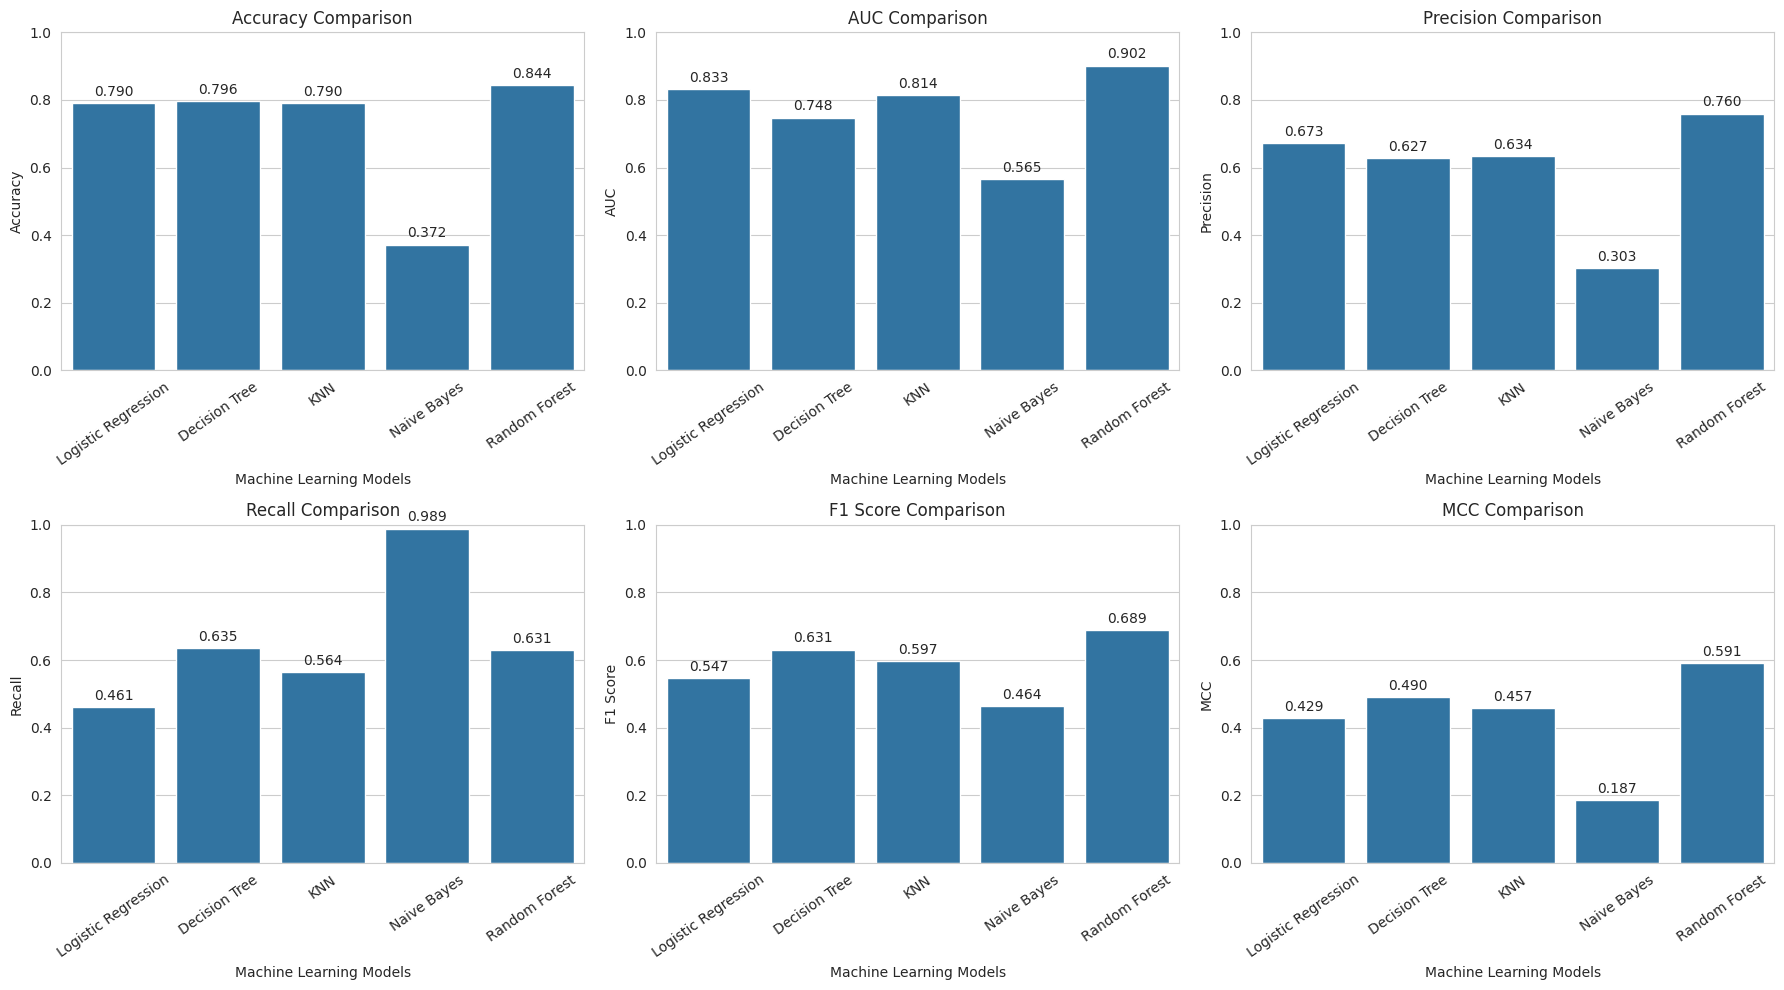

In [42]:
# Metrics to visualize
metrics = [
    'Accuracy',
    'AUC',
    'Precision',
    'Recall',
    'F1 Score',
    'MCC'
]

# Create a figure with 6 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Generate one graph for each metric
for ax, metric in zip(axes.flat, metrics):

    sns.barplot(
        x=comparison_df.index,
        y=comparison_df[metric],
        ax=ax
    )

    ax.set_title(f'{metric} Comparison')
    ax.set_xlabel('Machine Learning Models')
    ax.set_ylabel(metric)

    # All your current metric values are positive
    if metric == 'MCC':
        ax.set_ylim(0, 1)
    else:
        ax.set_ylim(0, 1)

    ax.tick_params(axis='x', rotation=35)

    # Display values above bars
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3)

# Adjust spacing
plt.tight_layout()

# Display all graphs
plt.show()

In [43]:
fig.savefig(
    'model_comparison_visualization.png',
    dpi=300,
    bbox_inches='tight'
)

In [44]:
print("MODEL PERFORMANCE OBSERVATIONS")

display(comparison_df)

MODEL PERFORMANCE OBSERVATIONS


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.7901,0.8328,0.6726,0.4606,0.5468,0.4290
Decision Tree,0.7960,0.7478,0.6274,0.6350,0.6312,0.4902
KNN,0.7905,0.8144,0.6336,0.5640,0.5968,0.4573
Naive Bayes,0.3724,0.5653,0.3032,0.9888,0.4641,0.1868
Random Forest,0.8437,0.9019,0.7598,0.6308,0.6893,0.5907


**Observations for each model**
1. Logistic Regression
- Achieved 79.01% accuracy.
- Obtained an AUC of 0.8328.
- Its recall is 46.06%, indicating that it misses several actual booking cancellations.
- It provides reasonable classification performance but is not the best-performing model.
2. Decision Tree
- Achieved 79.60% accuracy.
- Obtained 63.50% recall.
- It identifies more actual cancellations than Logistic Regression.
- Its AUC of 0.7478 indicates comparatively weaker class discrimination.
3. K-Nearest Neighbors (KNN)
- Achieved 79.05% accuracy.
- Obtained an AUC of 0.8144.
- Its F1 Score is 0.5968.
- It provides reasonable performance but does not outperform Random Forest.
4. Naive Bayes
- Achieved 37.24% accuracy.
- Obtained the highest recall of 98.88%.
- Its precision is only 30.32%, indicating many false-positive predictions.
- It identifies almost all actual cancellations but has poor overall classification performance.
5. Random Forest
- Achieved the highest accuracy of 84.37%.
- Obtained the highest AUC of 0.9019.
- Achieved the highest precision of 75.98%.
- Obtained an F1 Score of 0.6893 and MCC of 0.5907.
- It provides the best overall balance among the five models.

In [45]:
# Find the model with the highest value for each metric
best_models = comparison_df.idxmax()

print("BEST MODEL FOR EACH EVALUATION METRIC")

for metric, model in best_models.items():
    print(f"{metric}: {model}")

# Identify the overall winner based on the highest accuracy
overall_winner = comparison_df['Accuracy'].idxmax()

print("\nOVERALL WINNER:", overall_winner)

BEST MODEL FOR EACH EVALUATION METRIC
Accuracy: Random Forest
AUC: Random Forest
Precision: Random Forest
Recall: Naive Bayes
F1 Score: Random Forest
MCC: Random Forest

OVERALL WINNER: Random Forest


**Final conclusion**

The performance of five machine learning classification algorithms was compared for predicting hotel booking cancellations.

Among the five models, Random Forest achieved the highest accuracy, AUC, precision, F1 Score, and MCC. Therefore, it demonstrated the best overall classification performance.

Naive Bayes achieved the highest recall of 98.88%, which means it correctly identified almost all actual cancellations. However, its low precision of 30.32% indicates that it also incorrectly classified many non-canceled bookings as canceled.

Based on the overall evaluation, Random Forest was selected as the best-performing model for this hotel booking cancellation prediction task.

In [46]:
# Create a copy of the testing features
test_data = X_test.copy()

# Add the actual target column
test_data['is_canceled'] = y_test

# Save the test dataset
test_data.to_csv('test_data.csv', index=False)

print("Test data saved successfully!")
print("Test data shape:", test_data.shape)

display(test_data.head())

Test data saved successfully!
Test data shape: (17480, 26)


,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,customer_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled
117514,City Hotel,243,2017,August,31,4,0,1,2,0.0,0,BB,NLD,Online TA,TA/TO,0,0,0,A,No Deposit,9.0,Transient-Party,112.5,0,1,0
106099,City Hotel,44,2017,February,7,17,2,2,2,2.0,0,BB,FRA,Online TA,TA/TO,0,0,0,F,No Deposit,9.0,Transient,149.6,0,0,0
38748,Resort Hotel,163,2017,July,30,24,1,4,2,2.0,0,BB,POL,Online TA,TA/TO,0,0,0,C,No Deposit,240.0,Transient,214.0,0,1,0
9323,Resort Hotel,44,2016,November,46,12,2,1,2,0.0,0,BB,ESP,Online TA,TA/TO,0,0,0,A,No Deposit,240.0,Transient,37.8,0,3,1
7705,Resort Hotel,67,2016,August,35,21,4,6,2,0.0,0,BB,FRA,Direct,Direct,0,0,0,C,No Deposit,250.0,Transient,197.1,0,0,1


In [47]:
import os
import joblib

In [48]:
os.makedirs('models', exist_ok=True)

In [49]:
# Save preprocessing pipeline
joblib.dump(preprocessor, 'models/preprocessor.pkl')

# Save Logistic Regression
joblib.dump(logistic_model, 'models/logistic_regression.pkl')

# Save Decision Tree
joblib.dump(decision_tree_model, 'models/decision_tree.pkl')

# Save KNN
joblib.dump(knn_model, 'models/knn.pkl')

# Save Naive Bayes
joblib.dump(naive_bayes_model, 'models/naive_bayes.pkl')

# Save Random Forest
joblib.dump(random_forest_model, 'models/random_forest.pkl')

print("All trained models saved successfully!")

All trained models saved successfully!


In [50]:
comparison_df.to_csv('model_comparison.csv')

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [51]:
from google.colab import files

files.download('test_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
import shutil

shutil.make_archive('models', 'zip', 'models')

files.download('models.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>